In [2]:
import seaborn as sb
import numpy as np
import random
import math
import pandas as pd
import matplotlib.pyplot as plt
import scipy as sc

In [ ]:
#1. Моделировать выборку из а) распределения exp(1) б) распределения Коши с помощью метода
#обратной функции. Построить гистограмму, сравнить со встроенным методом.

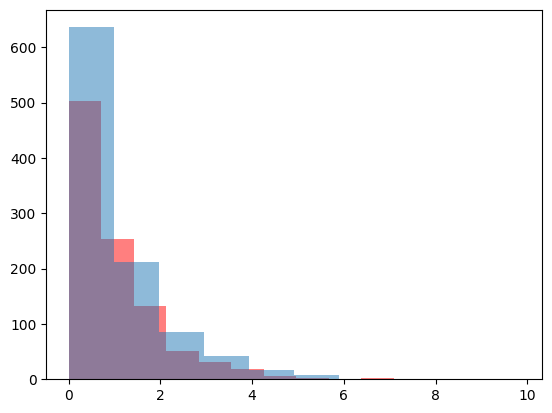

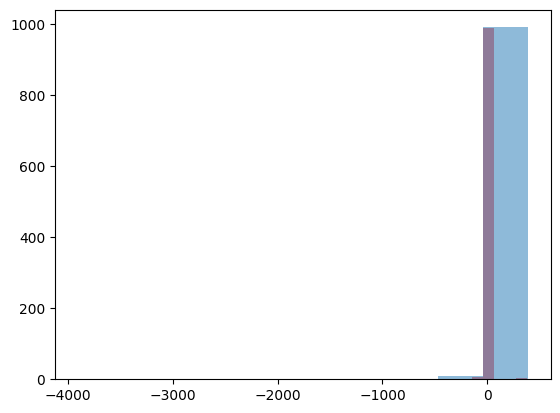

In [2]:
x = np.random.uniform(0, 1, size = 1000)
y = np.random.exponential(scale = 1, size = 1000)
plt.hist([(-1)*np.log(1-a) for a in x], alpha = 0.5, color = "red" )
plt.hist(y, alpha = 0.5)
plt.show()

y = np.random.standard_cauchy(size = 1000)
plt.hist([np.tan(np.pi*(a-1/2)) for a in x], alpha = 0.5, color = "red")
plt.hist(y, alpha = 0.5)
plt.show()

In [ ]:
#2. Моделировать выборку из равномерного распределения на единичном круге: а) методом выбора с
#отклонениями, б)* методом условных распределений, в) с помощью полярных координат.


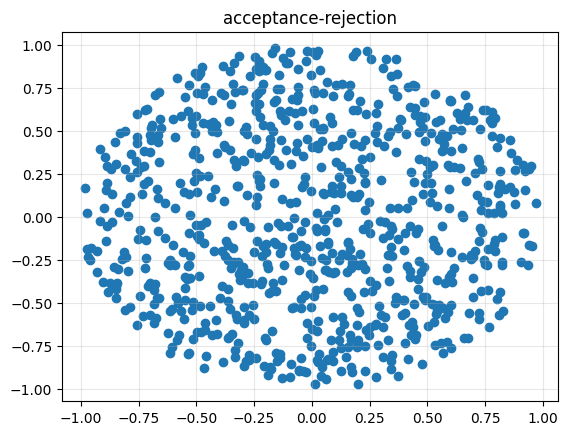

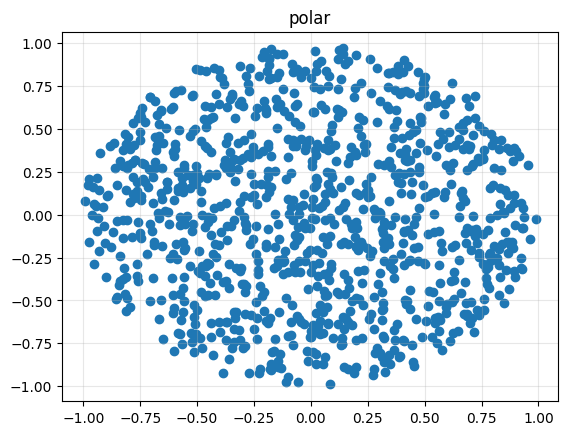

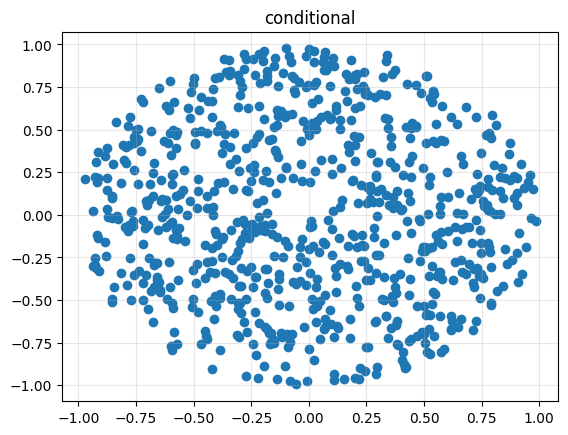

In [3]:
n = 1000
x = np.random.uniform(-1,1, size = n)
y = np.random.uniform(-1,1, size = n)

def picture(ar_x, ar_y, word):
    plt.scatter(ar_x, ar_y)
    plt.title(word)
    plt.grid(True, alpha=0.3)
    plt.show()

#acceptance-rejection
data_ara_x = []
data_ara_y = []
for i in range(n):
    if (x[i]**2 + y[i]**2 <=1):
        data_ara_x.append(x[i])
        data_ara_y.append(y[i])
picture(data_ara_x, data_ara_y, "acceptance-rejection")

#polar
r = np.random.uniform(0,1, size = n)
phi = np.random.uniform(0,2*np.pi, size = n)
data_polar_x = [np.sqrt(r[i])*np.cos(phi[i])for i in range(n)]
data_polar_y = [np.sqrt(r[i])*np.sin(phi[i]) for i in range(n)]
picture(data_polar_x, data_polar_y, "polar")



a=np.random.uniform(-1,1, size = n)
data_cond_x = []
data_cond_y = []
for i in range(n):
    if (np.random.binomial(1,np.sqrt(1-a[i]**2)) ==1):
        data_cond_x.append(a[i])
        data_cond_y.append(np.random.uniform(-np.sqrt(1-a[i]**2), np.sqrt(1-a[i]**2)))
picture(data_cond_x, data_cond_y, "conditional")

In [13]:
'''
n = 1000

def picture(ar_x, ar_y, word):
    plt.scatter(ar_x, ar_y, color='blue')
    plt.title(word)
    plt.grid(True, alpha=0.3)
    plt.show()
    
def equation(t, u):
    return (t * np.sqrt(1 - t**2) + np.arcsin(t) + np.pi/2) / np.pi - u
    
def quantile_function(equation, data, tol=1e-10):
    u_array = np.asarray(data)
    result = np.zeros_like(u_array)
    for i, u in enumerate(u_array):
        result[i] = sc.optimize.bisect(equation, -1, 1, args=(u,), xtol=tol)
    return result
    
data = np.random.uniform(-1,1, size = n)
x = quantile_function(equation, data, tol=1e-10)
y = [0]*n
for k in range(n):
    y[k]=np.random.uniform(-np.sqrt(1-x[k]**2), np.sqrt(1-x[k]**2))
picture(x,y,"cond")
'''

'\nn = 1000\n\ndef picture(ar_x, ar_y, word):\n    plt.scatter(ar_x, ar_y, color=\'blue\')\n    plt.title(word)\n    plt.grid(True, alpha=0.3)\n    plt.show()\n\ndef equation(t, u):\n    return (t * np.sqrt(1 - t**2) + np.arcsin(t) + np.pi/2) / np.pi - u\n\ndef quantile_function(equation, data, tol=1e-10):\n    u_array = np.asarray(data)\n    result = np.zeros_like(u_array)\n    for i, u in enumerate(u_array):\n        result[i] = sc.optimize.bisect(equation, -1, 1, args=(u,), xtol=tol)\n    return result\n\ndata = np.random.uniform(-1,1, size = n)\nx = quantile_function(equation, data, tol=1e-10)\ny = [0]*n\nfor k in range(n):\n    y[k]=np.random.uniform(-np.sqrt(1-x[k]**2), np.sqrt(1-x[k]**2))\npicture(x,y,"cond")\n'

In [12]:
#3. Моделировать выборку с плотностью а) Лапласа б) exp(−x)/2, x > 0 и exp(2x), x < 0. Построить
#гистограмму. (Использовать смеси распределений.) 

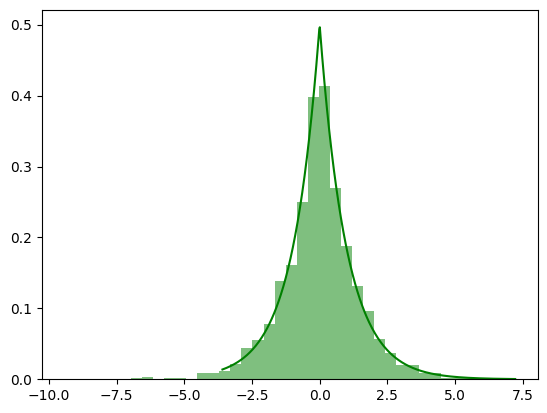

In [21]:
n = 3000
b = 1
def mixed_exp(m):
    sample = [0]*m
    for i in range(m):
        if np.random.binomial(1, 0.5) <= 0.5:
            sample[i] = np.random.exponential(scale=1)
        else:
            sample[i] = (-1)*np.random.exponential(scale=0.5)
    return sample 

def mixed_lap(m):
    sample = [0]*m
    for i in range(m):
        if np.random.binomial(1, 0.5) == 0.0:
            sample[i] = np.random.exponential(scale=1)
        else:
            sample[i] = (-1)*np.random.exponential(scale=1)
    return sample 
    
y = mixed_exp(n)
x = np.linspace(np.min(y), np.max(y), 500)
z = mixed_lap(n)
#plt.hist(y, density = "true", color = "blue", alpha = 0.5, bins= 40)
plt.hist(z, density = "true", color = "green", alpha = 0.5, bins= 40)
plt.plot(x, sc.stats.laplace.pdf(x, loc = 0, scale = 1), color = "green")
plt.show()

In [ ]:
#5. Смоделировать с помощью алгоритма Acceptance-Rejection выборку из а) треугольного распреде-
#ления (c плотностью (1 − |x|) I(x ∈ [−1, 1])); б)* нормального распределения с помощью распреде-
#ления Лапласа.

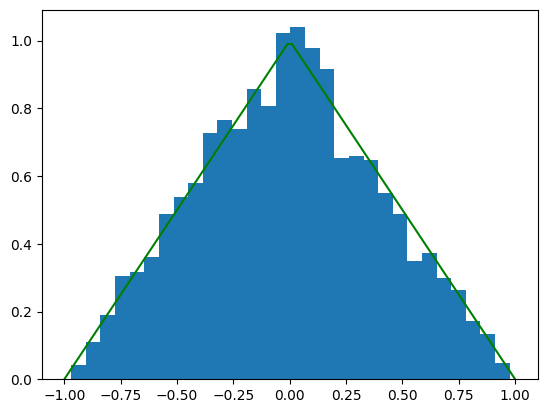

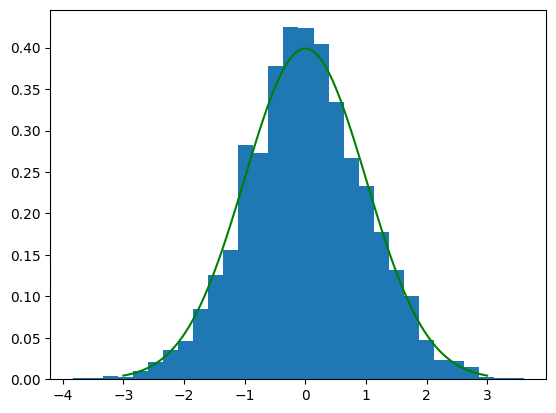

In [6]:
n = 5000
y = np.random.uniform(-1,1,size = n)
data = []
for i in range(n):
    if(np.random.binomial(1, (1 - np.abs(y[i])) ) == 1):
        data.append(y[i])
plt.hist(data, density = "true", bins = 30)
x = np.linspace(-1,1,100)
plt.plot(x, 1 - np.abs(x), color = "green")
plt.show()

y = np.random.laplace(0,1,size = n)
data = []
for i in range(n):
    if(np.random.binomial(1, sc.stats.norm.pdf(y[i], 0,1) / (sc.stats.laplace.pdf(y[i], 0,1)*np.sqrt(2*np.e/np.pi)) )  == 1):
        data.append(y[i])
plt.hist(data, density = "true", bins = 30)
x = np.linspace(-3,3,100)
plt.plot(x, sc.stats.norm.pdf(x, 0, 1), color = "green")
plt.show()

In [ ]:
#4. * Моделировать выборку с плотностью
#треть нормального и две трети лапласа
#Построить гистограмму

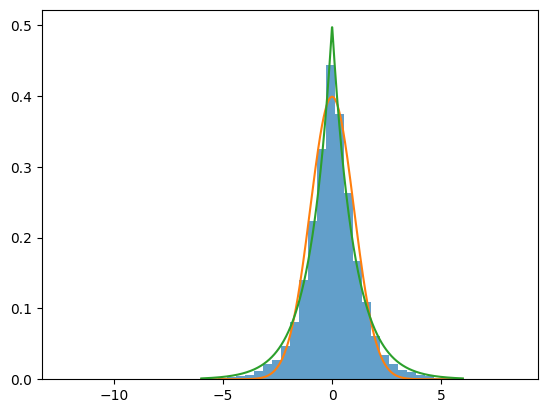

In [8]:
n = 10000
sample = []
for _ in range(n):
    if np.random.uniform(0, 1) < 1/3: 
        sample.append(np.random.normal(0, 1))
    else: 
        sample.append(np.random.laplace(0, 1))
plt.hist(sample, bins=50, density=True, alpha=0.7)
x = np.linspace(-6, 6, 1000)
plt.plot(x, sc.stats.norm.pdf(x, loc = 0 , scale = 1))
plt.plot(x, sc.stats.laplace.pdf(x, loc = 0 , scale = 1))
plt.show()